# Predicting Diabetes with Machine Learning

**Goal:** predict whether a patient has diabetes (`Outcome = 1`) from eight diagnostic measurements, using the Pima Indians Diabetes Database (768 female patients of Pima Indian heritage, aged 21 and older).

**Approach**
1. Explore the data and find hidden missing values (zeros that are physically impossible).
2. Split the data **first**, so that the test set is never used for any preprocessing or model choice.
3. Put all preprocessing (missing values, outlier capping, scaling) inside scikit-learn pipelines.
4. Compare eight models with **repeated stratified cross-validation** instead of a single split.
5. Choose a decision threshold that catches more diabetic patients, then evaluate the final model **once** on the test set.

**Contents**
1. Setup and data
2. Exploratory analysis
3. Train / test split
4. Preprocessing pipeline
5. Why a single split is not enough
6. Model comparison with cross-validation
7. Choosing the decision threshold
8. Final evaluation on the test set
9. Which features matter?
10. Conclusion

## 1. Setup and data

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import (GradientBoostingClassifier, RandomForestClassifier,
                              VotingClassifier)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, roc_curve,
                             classification_report, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

try:
    from xgboost import XGBClassifier
except ImportError:              # XGBoost is optional
    XGBClassifier = None

# Hide version-related warnings (also in the parallel worker processes)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
os.environ["PYTHONWARNINGS"] = "ignore::UserWarning,ignore::FutureWarning"
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
IMG_DIR = Path("images"); IMG_DIR.mkdir(exist_ok=True)

The dataset is the [Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database) (originally from the National Institute of Diabetes and Digestive and Kidney Diseases). If `data/diabetes.csv` does not exist, it is downloaded with `kagglehub`.

| Column | Meaning |
|---|---|
| Pregnancies | Number of pregnancies |
| Glucose | Plasma glucose concentration, 2 hours into an oral glucose tolerance test |
| BloodPressure | Diastolic blood pressure (mm Hg) |
| SkinThickness | Triceps skinfold thickness (mm) |
| Insulin | 2-hour serum insulin (µU/ml) |
| BMI | Body mass index (kg/m²) |
| DiabetesPedigreeFunction | Score for diabetes in the family history |
| Age | Age (years) |
| Outcome | 1 = diabetes, 0 = no diabetes |

In [2]:
DATA_PATH = Path("data/diabetes.csv")
if not DATA_PATH.exists():
    import kagglehub
    DATA_PATH = Path(kagglehub.dataset_download("uciml/pima-indians-diabetes-database")) / "diabetes.csv"

df = pd.read_csv(DATA_PATH)
print(f"{df.shape[0]} patients, {df.shape[1] - 1} features")
df.head()

768 patients, 8 features


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Exploratory analysis

### Hidden missing values

The dataset has no empty cells, but several columns contain **zeros that are physically impossible**: nobody has a glucose level, blood pressure or BMI of 0. These zeros are missing measurements.

In [3]:
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

missing = (df[ZERO_AS_MISSING] == 0).sum().to_frame("zeros")
missing["share"] = (missing["zeros"] / len(df)).map("{:.1%}".format)
missing

,zeros,share
Glucose,5,0.7%
BloodPressure,35,4.6%
SkinThickness,227,29.6%
Insulin,374,48.7%
BMI,11,1.4%


Almost **half of the Insulin values** and **30% of SkinThickness** are missing. Filling them with one value (the median) makes these two columns much less informative, so the pipeline also adds a *missing indicator* column for each feature. It tells the model which values were filled in, because whether a test was done can itself carry information.

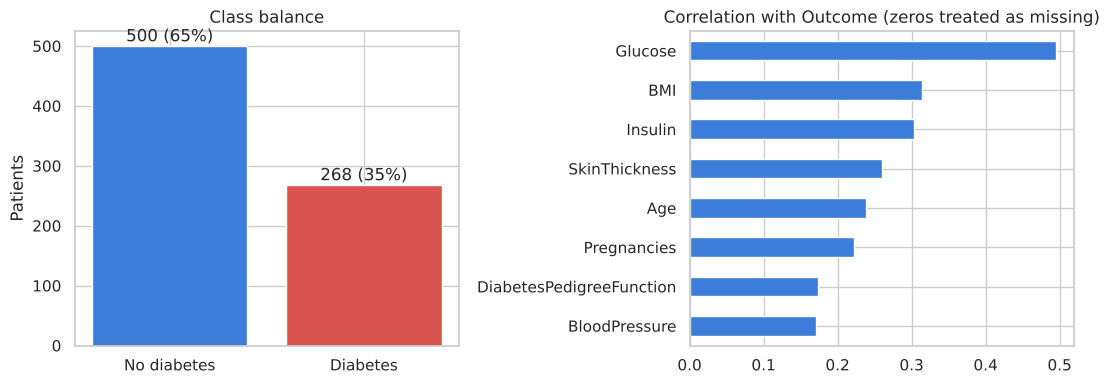

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts = df["Outcome"].map({0: "No diabetes", 1: "Diabetes"}).value_counts()
axes[0].bar(counts.index, counts.values, color=["#3b7dd8", "#d9534f"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 8, f"{v} ({v / len(df):.0%})", ha="center")
axes[0].set_title("Class balance")
axes[0].set_ylabel("Patients")

corr = df.replace({c: {0: np.nan} for c in ZERO_AS_MISSING}).corr()["Outcome"].drop("Outcome")
corr.sort_values().plot.barh(ax=axes[1], color="#3b7dd8")
axes[1].set_title("Correlation with Outcome (zeros treated as missing)")
plt.tight_layout()
plt.savefig(IMG_DIR / "class_balance_correlation.png", dpi=120, bbox_inches="tight")
plt.show()

The classes are imbalanced (65% / 35%), so **accuracy alone is misleading**: a model that always says "no diabetes" would already reach 65%. The comparison below therefore also reports recall, F1 and ROC AUC.

Glucose has by far the strongest relationship with the outcome, followed by BMI and Insulin. Insulin looks strong here only because its many missing values are excluded; with half the values filled in, it carries much less information for the models.

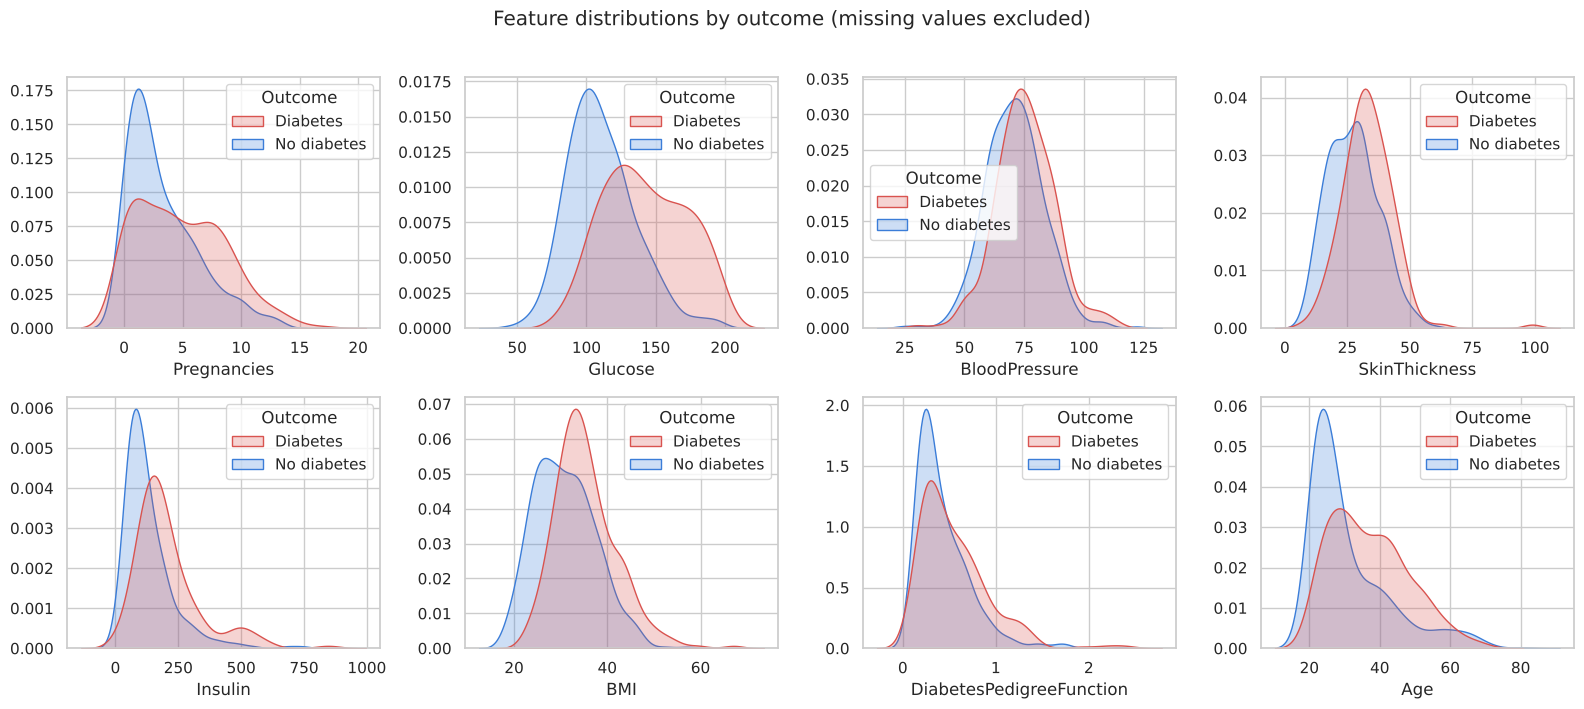

In [5]:
features = [c for c in df.columns if c != "Outcome"]
plot_df = df.replace({c: {0: np.nan} for c in ZERO_AS_MISSING})
plot_df["Outcome"] = plot_df["Outcome"].map({0: "No diabetes", 1: "Diabetes"})

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.kdeplot(data=plot_df, x=col, hue="Outcome", common_norm=False, fill=True,
                palette={"No diabetes": "#3b7dd8", "Diabetes": "#d9534f"}, ax=ax, warn_singular=False)
    ax.set_ylabel("")
plt.suptitle("Feature distributions by outcome (missing values excluded)", y=1.01)
plt.tight_layout()
plt.savefig(IMG_DIR / "feature_distributions.png", dpi=110, bbox_inches="tight")
plt.show()

## 3. Train / test split

The split happens **before any preprocessing**. If missing values were filled or outliers capped on the full dataset, information from the test patients would leak into training. 20% of the patients are kept as a test set, stratified so both parts have the same share of diabetic patients, and with a fixed `random_state` so the results are reproducible.

In [6]:
X = df.drop(columns="Outcome")
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train)} patients ({y_train.mean():.1%} diabetic)")
print(f"Test:  {len(X_test)} patients ({y_test.mean():.1%} diabetic)")

Train: 614 patients (34.9% diabetic)
Test:  154 patients (35.1% diabetic)


## 4. Preprocessing pipeline

Every model gets the same preprocessing steps, fitted on the training data only:

1. **Zeros → missing** in the five columns above.
2. **Outlier capping** with the IQR rule (values beyond 1.5 × IQR are set to the limit). The limits are learned on the training data, and missing values are ignored.
3. **Median imputation** plus a missing-indicator column for each feature with missing values.
4. **Standard scaling**, which KNN, SVM and Logistic Regression need because they work with distances or weights. Tree models are not affected by it.

In [7]:
class ZeroToNaN(BaseEstimator, TransformerMixin):
    # Replace physically impossible zeros with NaN.
    def __init__(self, columns):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X[self.columns] = X[self.columns].replace(0, np.nan)
        return X


class IQRCapper(BaseEstimator, TransformerMixin):
    # Cap values outside [Q1 - k*IQR, Q3 + k*IQR]; the limits are learned in fit().
    def __init__(self, k=1.5):
        self.k = k

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.nanpercentile(X, 25, axis=0), np.nanpercentile(X, 75, axis=0)
        iqr = q3 - q1
        self.low_, self.high_ = q1 - self.k * iqr, q3 + self.k * iqr
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)   # NaN stays NaN


def make_pipeline(model):
    return Pipeline([
        ("zeros", ZeroToNaN(ZERO_AS_MISSING)),
        ("cap", IQRCapper()),
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
        ("model", model),
    ])

## 5. Why a single split is not enough

With only 154 test patients, one patient more or less correctly classified changes accuracy by 0.65 percentage points. To see how much a single result depends on luck, the same Random Forest is trained and tested on 50 different random splits.

Random Forest accuracy over 50 random splits: mean 75.9%, min 71.4%, max 81.8%


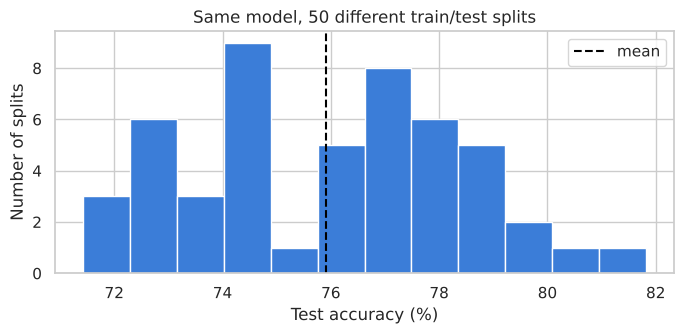

In [8]:
split_scores = []
for seed in range(50):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.20, stratify=y, random_state=seed)
    pipe = make_pipeline(RandomForestClassifier(n_estimators=300, max_depth=4, random_state=RANDOM_STATE))
    split_scores.append(accuracy_score(yb, pipe.fit(Xa, ya).predict(Xb)))
split_scores = np.array(split_scores)

print(f"Random Forest accuracy over 50 random splits: "
      f"mean {split_scores.mean():.1%}, min {split_scores.min():.1%}, max {split_scores.max():.1%}")

plt.figure(figsize=(7, 3.5))
plt.hist(split_scores * 100, bins=12, color="#3b7dd8", edgecolor="white")
plt.axvline(split_scores.mean() * 100, color="black", linestyle="--", label="mean")
plt.xlabel("Test accuracy (%)")
plt.ylabel("Number of splits")
plt.title("Same model, 50 different train/test splits")
plt.legend()
plt.tight_layout()
plt.savefig(IMG_DIR / "split_variability.png", dpi=120, bbox_inches="tight")
plt.show()

The **same model** scores anywhere in a range of about 10 percentage points, depending only on which patients land in the test set. Differences of 1–3 points between models on one split are therefore mostly noise. The models are compared with **repeated stratified 5-fold cross-validation** (5 folds × 10 repetitions = 50 scores per model) on the training set instead.

## 6. Model comparison with cross-validation

In [9]:
base_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=4, random_state=RANDOM_STATE),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
if XGBClassifier is not None:
    base_models["XGBoost"] = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                                           eval_metric="logloss", random_state=RANDOM_STATE)
base_models["Voting (LR + RF + SVM)"] = VotingClassifier(
    [("lr", LogisticRegression(max_iter=1000)),
     ("rf", RandomForestClassifier(n_estimators=300, max_depth=4, random_state=RANDOM_STATE)),
     ("svm", SVC(probability=True, random_state=RANDOM_STATE))],
    voting="soft")

pipelines = {name: make_pipeline(m) for name, m in base_models.items()}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
metrics = {"Accuracy": "accuracy", "Recall": "recall", "F1": "f1", "ROC AUC": "roc_auc"}

cv_raw, rows = {}, {}
for name, pipe in pipelines.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metrics, n_jobs=-1)
    cv_raw[name] = res["test_ROC AUC"]
    rows[name] = {m: f"{res['test_' + m].mean():.3f} ± {res['test_' + m].std():.3f}" for m in metrics}

cv_table = pd.DataFrame(rows).T.sort_values("ROC AUC", ascending=False)
print("Cross-validation on the training set (mean ± standard deviation over 50 folds)")
cv_table

Cross-validation on the training set (mean ± standard deviation over 50 folds)


,Accuracy,Recall,F1,ROC AUC
Voting (LR + RF + SVM),0.776 ± 0.030,0.564 ± 0.073,0.635 ± 0.057,0.843 ± 0.030
Logistic Regression,0.784 ± 0.034,0.592 ± 0.071,0.655 ± 0.058,0.838 ± 0.032
Random Forest,0.767 ± 0.029,0.511 ± 0.073,0.602 ± 0.060,0.836 ± 0.032
SVM,0.765 ± 0.033,0.577 ± 0.071,0.630 ± 0.055,0.831 ± 0.028
XGBoost,0.754 ± 0.034,0.589 ± 0.077,0.623 ± 0.058,0.820 ± 0.030
Gradient Boosting,0.754 ± 0.032,0.586 ± 0.076,0.622 ± 0.056,0.819 ± 0.033
KNN,0.756 ± 0.029,0.515 ± 0.070,0.593 ± 0.055,0.812 ± 0.035
Decision Tree,0.731 ± 0.038,0.569 ± 0.119,0.591 ± 0.067,0.773 ± 0.042


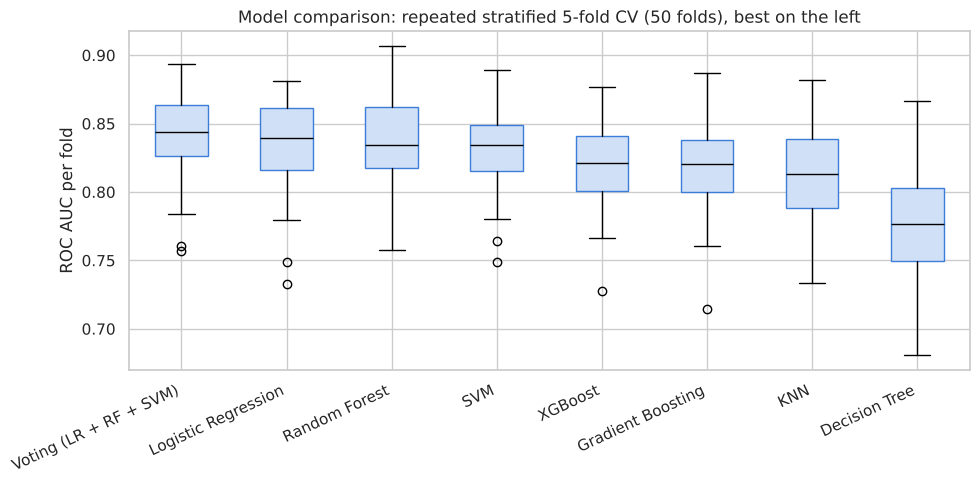

In [10]:
order = cv_table.index
plt.figure(figsize=(10, 5))
plt.boxplot([cv_raw[n] for n in order], patch_artist=True,
            boxprops=dict(facecolor="#cfe0f7", color="#3b7dd8"), medianprops=dict(color="black"))
plt.xticks(range(1, len(order) + 1), order, rotation=25, ha="right")
plt.ylabel("ROC AUC per fold")
plt.title("Model comparison: repeated stratified 5-fold CV (50 folds), best on the left")
plt.tight_layout()
plt.savefig(IMG_DIR / "model_comparison_cv.png", dpi=120, bbox_inches="tight")
plt.show()

**ROC AUC** measures how well a model ranks diabetic patients above non-diabetic ones, independent of the decision threshold. The boxes overlap strongly, so most models perform similarly on this dataset. The best model is chosen by mean ROC AUC.

In [11]:
best_name = cv_table.index[0]
best_pipe = pipelines[best_name]
print("Best model by cross-validated ROC AUC:", best_name)

Best model by cross-validated ROC AUC: Voting (LR + RF + SVM)


## 7. Choosing the decision threshold

By default a classifier predicts "diabetes" when its probability is above 0.5. For a **screening** tool, missing a diabetic patient (false negative) is worse than a false alarm, which a follow-up test can rule out. So the threshold is lowered until the model finds at least **80% of the diabetic patients** (recall ≥ 0.80).

The threshold is chosen with out-of-fold predictions on the **training set**, so the test set stays untouched.

Chosen threshold: 0.28 (highest threshold with recall >= 80% in CV)


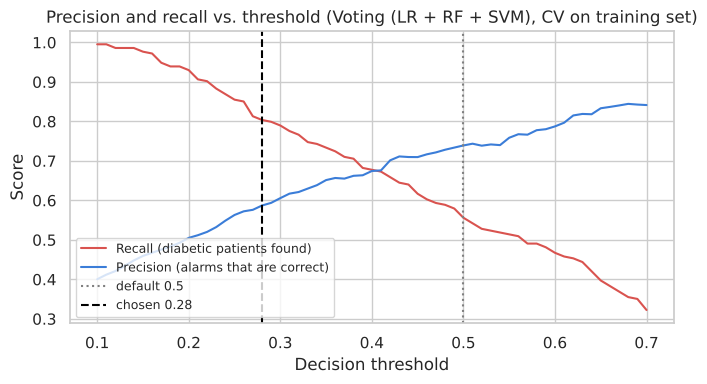

In [12]:
TARGET_RECALL = 0.80

oof_proba = cross_val_predict(best_pipe, X_train, y_train, method="predict_proba",
                              cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))[:, 1]

thresholds = np.round(np.arange(0.10, 0.71, 0.01), 2)
curve = pd.DataFrame({
    "threshold": thresholds,
    "recall": [recall_score(y_train, oof_proba >= t) for t in thresholds],
    "precision": [precision_score(y_train, oof_proba >= t) for t in thresholds],
})
THRESHOLD = curve.loc[curve["recall"] >= TARGET_RECALL, "threshold"].max()
print(f"Chosen threshold: {THRESHOLD:.2f} (highest threshold with recall >= {TARGET_RECALL:.0%} in CV)")

plt.figure(figsize=(7, 4))
plt.plot(curve["threshold"], curve["recall"], label="Recall (diabetic patients found)", color="#d9534f")
plt.plot(curve["threshold"], curve["precision"], label="Precision (alarms that are correct)", color="#3b7dd8")
plt.axvline(0.5, color="grey", linestyle=":", label="default 0.5")
plt.axvline(THRESHOLD, color="black", linestyle="--", label=f"chosen {THRESHOLD:.2f}")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title(f"Precision and recall vs. threshold ({best_name}, CV on training set)")
plt.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.savefig(IMG_DIR / "threshold.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Final evaluation on the test set

The chosen model is trained on the full training set and evaluated **once** on the 154 test patients, with the default threshold (0.5) and with the screening threshold.

In [13]:
best_pipe.fit(X_train, y_train)
test_proba = best_pipe.predict_proba(X_test)[:, 1]

results = {}
for label, t in [("Default threshold 0.50", 0.50), (f"Screening threshold {THRESHOLD:.2f}", THRESHOLD)]:
    pred = (test_proba >= t).astype(int)
    results[label] = {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                      "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred)}
test_results = pd.DataFrame(results).T.round(3)
print(f"{best_name}, test set: ROC AUC = {roc_auc_score(y_test, test_proba):.3f}\n")
test_results

Voting (LR + RF + SVM), test set: ROC AUC = 0.814



,Accuracy,Precision,Recall,F1
Default threshold 0.50,0.727,0.630,0.537,0.580
Screening threshold 0.28,0.727,0.575,0.852,0.687


              precision    recall  f1-score   support

 No diabetes      0.892     0.660     0.759       100
    Diabetes      0.575     0.852     0.687        54

    accuracy                          0.727       154
   macro avg      0.733     0.756     0.723       154
weighted avg      0.781     0.727     0.733       154



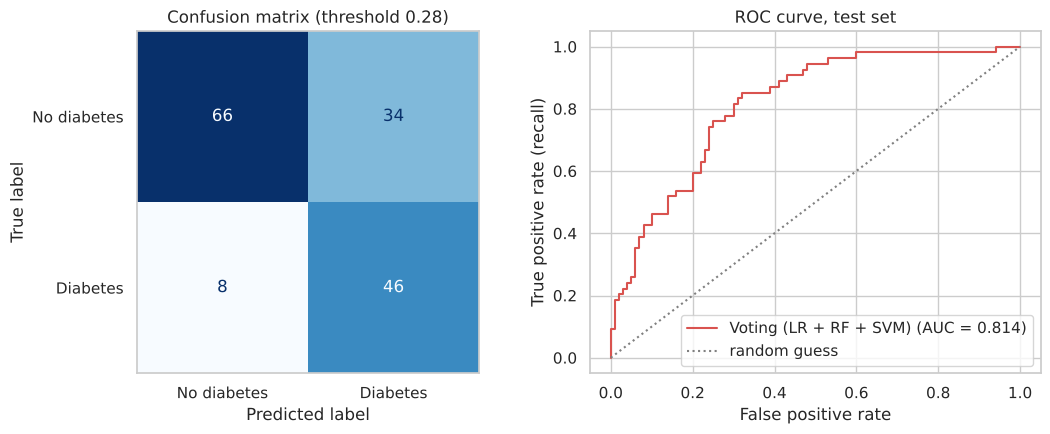

In [14]:
y_pred = (test_proba >= THRESHOLD).astype(int)
print(classification_report(y_test, y_pred, target_names=["No diabetes", "Diabetes"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No diabetes", "Diabetes"],
                                        cmap="Blues", values_format="d", colorbar=False, ax=axes[0])
axes[0].set_title(f"Confusion matrix (threshold {THRESHOLD:.2f})")
axes[0].grid(False)
fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, color="#d9534f", label=f"{best_name} (AUC = {roc_auc_score(y_test, test_proba):.3f})")
axes[1].plot([0, 1], [0, 1], linestyle=":", color="grey", label="random guess")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].legend(loc="lower right")
axes[1].set_title("ROC curve, test set")
plt.tight_layout()
plt.savefig(IMG_DIR / "test_results.png", dpi=120, bbox_inches="tight")
plt.show()

## 9. Which features matter?

**Permutation importance** shuffles one feature at a time in the test set and measures how much ROC AUC drops. A large drop means the model relies on that feature.

Glucose                     0.120
BMI                         0.029
Age                         0.019
Pregnancies                 0.017
DiabetesPedigreeFunction    0.013
Insulin                     0.005
BloodPressure               0.002
SkinThickness              -0.005


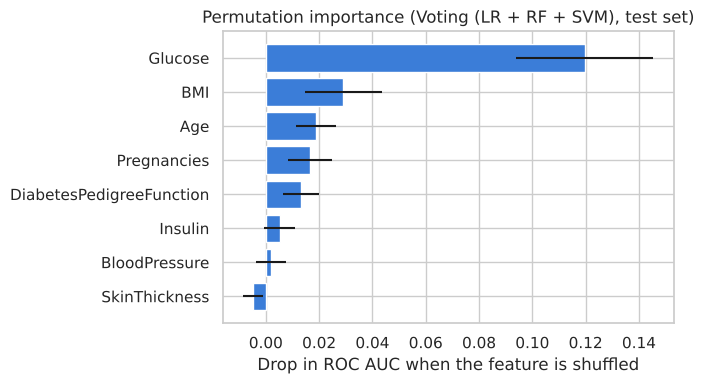

In [15]:
perm = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc",
                              n_repeats=30, random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

print(importance.sort_values(ascending=False).round(3).to_string())
plt.figure(figsize=(7, 4))
plt.barh(importance.index, importance.values, xerr=perm.importances_std[importance.index.map(X_test.columns.get_loc)],
         color="#3b7dd8")
plt.xlabel("Drop in ROC AUC when the feature is shuffled")
plt.title(f"Permutation importance ({best_name}, test set)")
plt.tight_layout()
plt.savefig(IMG_DIR / "feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()

## 10. Conclusion

* **Data quality matters more than the model.** The dataset hides many missing values as zeros, especially Insulin (49%) and SkinThickness (30%). Treating them as missing, and fitting all preprocessing on the training data only, gives an honest evaluation.
* **One split is not enough.** On this small dataset the same model's accuracy varies by about 10 points between random splits, so models are compared with repeated cross-validation.
* **Most models perform similarly** (cross-validated ROC AUC between 0.81 and 0.84; only the single Decision Tree is clearly weaker). A well-preprocessed Logistic Regression is practically as good as the ensembles.
* **The threshold is a medical decision.** Lowering it finds more diabetic patients at the cost of more false alarms, which suits a screening tool.
* **Glucose is by far the most important feature**, followed by BMI and Age, which matches medical knowledge.

**Limitations:** 768 patients from one specific population (Pima Indian women aged 21+), so the model should not be assumed to work for other groups. It is a learning project, not a medical tool.